# Shared regularization sweep (Phase 3)

Rule 3 of the task distribution: choose **one** `(lambda_f, lambda_w)` for all four methods from a
seed-616 comparison, maximizing the **mean over the four methods** of selected-checkpoint
ordinary-validation NDCG@10; ties are broken by the lower mean validation loss (at the selected
checkpoints).

* Grid: `lambda_f, lambda_w` in {1e-4, 1e-3, 1e-2, 1e-1} (16 pairs), seed 616.
* Budget 1,000,000 triplet-gradients, checkpoint every 20,000; checkpoint chosen by ordinary-validation
  NDCG@10 only. No test data is touched.
* One fixed setting per method, on the same step-size scale (from `salr.ipynb`, `bcd.ipynb` and an SGD/SAM
  pilot at lambda = 1e-3):

| method | setting |
|---|---|
| SGD  | lr = 16 |
| SAM  | lr = 16, rho = 0.2 |
| SALR | base_lr = 16, probe_step = 0.05, one-step probes |
| BCD  | max_inner = 1, inner_tol = 1e-4 |

Every run's log (configuration, traces, checkpoints, no parameters) is saved to
`results/logs/regularization/`.

In [1]:
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

from recommender.bcd import BCDConfig, train_bcd
from recommender.data import load_dataset
from recommender.evaluate import make_evaluator, select_checkpoint
from recommender.runlog import LOG_DIR, save_log
from recommender.salr import SALRConfig, train_salr
from recommender.sam import SAMConfig, train_sam
from recommender.sgd import SGDConfig, train_sgd

ds = load_dataset()
evaluate = make_evaluator(ds)
SEED = 616
TOTAL_WORK, CHECKPOINT_EVERY = 1_000_000, 20_000
GRID = (1e-4, 1e-3, 1e-2, 1e-1)
RESULTS = Path("results"); LOGS = LOG_DIR / "regularization"

METHODS = {
    "sgd":  lambda lf, lw: (train_sgd,  SGDConfig(16.0, lf, lw)),
    "sam":  lambda lf, lw: (train_sam,  SAMConfig(16.0, 0.2, lf, lw)),
    "salr": lambda lf, lw: (train_salr, SALRConfig(16.0, 0.05, lf, lw)),
    "bcd":  lambda lf, lw: (train_bcd,  BCDConfig(lf, lw, inner_tol=1e-4, max_inner=1)),
}

In [2]:
rows, started = [], time.perf_counter()
for lf in GRID:
    for lw in GRID:
        for method, make in METHODS.items():
            train, cfg = make(lf, lw)
            with np.errstate(all="ignore"):
                log = train(ds, SEED, cfg, TOTAL_WORK, CHECKPOINT_EVERY, evaluate)
            save_log(log, f"{method}_lf{lf:g}_lw{lw:g}_seed{SEED}", LOGS, experiment="regularization")
            best = select_checkpoint(log)
            rows.append({"lambda_f": lf, "lambda_w": lw, "method": method, "status": log["status"],
                         "val_ndcg": best["val_ndcg"], "val_recall": best["val_recall"],
                         "val_loss": best["val_loss"], "train_loss": best["train_loss"],
                         "selected_work": best["work"], "train_time_s": log["checkpoints"][-1]["train_time"]})
runs = pd.DataFrame(rows)
runs.to_csv(RESULTS / "regularization_runs.csv", index=False)
print(f"{len(runs)} runs in {time.perf_counter() - started:.0f}s; status counts:")
print(runs.status.value_counts().to_string())

64 runs in 509s; status counts:
status
ok           51
converged     7
failed        6


## Per-method NDCG@10 (rows: lambda_f, columns: lambda_w)

In [3]:
for method in METHODS:
    print(method)
    print(runs[runs.method == method].pivot(index="lambda_f", columns="lambda_w", values="val_ndcg").round(4), "\n")

sgd
lambda_w  0.0001  0.0010  0.0100  0.1000
lambda_f                                
0.0001    0.1221  0.1185  0.1159  0.1123
0.0010    0.1284  0.1436  0.1297  0.1224
0.0100    0.1215  0.0984  0.1074  0.1074
0.1000    0.0946  0.0946  0.0946  0.0946 

sam
lambda_w  0.0001  0.0010  0.0100  0.1000
lambda_f                                
0.0001    0.1235  0.1210  0.1162  0.1156
0.0010    0.1267  0.1363  0.1278  0.1258
0.0100    0.1315  0.0949  0.0983  0.0982
0.1000    0.0785  0.0785  0.0785  0.0785 

salr
lambda_w  0.0001  0.0010  0.0100  0.1000
lambda_f                                
0.0001    0.1190  0.1214  0.1172  0.0876
0.0010    0.1301  0.1435  0.1297  0.0835
0.0100    0.1306  0.1017  0.1104  0.1104
0.1000    0.0203  0.0203  0.0203  0.0203 

bcd
lambda_w  0.0001  0.0010  0.0100  0.1000
lambda_f                                
0.0001    0.1199  0.1194  0.1244  0.1234
0.0010    0.1151  0.1376  0.1221  0.1101
0.0100    0.1135  0.1033  0.0805  0.0805
0.1000    0.0805  0.0805  0.0805  

## Selection: mean over the four methods

In [4]:
pairs = (runs.groupby(["lambda_f", "lambda_w"])
         .agg(mean_ndcg=("val_ndcg", "mean"), min_ndcg=("val_ndcg", "min"),
              mean_val_loss=("val_loss", "mean"), failed=("status", lambda s: int((s == "failed").sum())))
         .reset_index()
         .sort_values(["mean_ndcg", "mean_val_loss"], ascending=[False, True]))
pairs.to_csv(RESULTS / "regularization_summary.csv", index=False)
chosen = pairs.iloc[0]
on_edge = chosen.lambda_f in (GRID[0], GRID[-1]) or chosen.lambda_w in (GRID[0], GRID[-1])
print(f"selected lambda_f = {chosen.lambda_f:g}, lambda_w = {chosen.lambda_w:g} "
      f"(mean NDCG@10 {chosen.mean_ndcg:.4f}); on the grid boundary: {on_edge}")
pairs.head(8).round(4)

selected lambda_f = 0.001, lambda_w = 0.001 (mean NDCG@10 0.1403); on the grid boundary: False


,lambda_f,lambda_w,mean_ndcg,min_ndcg,mean_val_loss,failed
5,0.0010,0.0010,0.1403,0.1363,0.5496,0
6,0.0010,0.0100,0.1273,0.1221,0.5536,0
4,0.0010,0.0001,0.1251,0.1151,0.6054,0
8,0.0100,0.0001,0.1243,0.1135,0.6234,0
0,0.0001,0.0001,0.1211,0.1190,0.6378,0
1,0.0001,0.0010,0.1201,0.1185,0.5824,0
2,0.0001,0.0100,0.1184,0.1159,0.7294,0
7,0.0010,0.1000,0.1104,0.0835,0.5755,1


In [5]:
runs[(runs.lambda_f == chosen.lambda_f) & (runs.lambda_w == chosen.lambda_w)].round(4)

,lambda_f,lambda_w,method,status,val_ndcg,val_recall,val_loss,train_loss,selected_work,train_time_s
20,0.001,0.001,sgd,ok,0.1436,0.2645,0.5421,0.2328,900012,4.5450
21,0.001,0.001,sam,ok,0.1363,0.2479,0.5437,0.2296,860424,4.3747
22,0.001,0.001,salr,ok,0.1435,0.2645,0.5475,0.2351,900012,9.7470
23,0.001,0.001,bcd,converged,0.1376,0.2562,0.5651,0.3265,141336,4.2424


## Figure

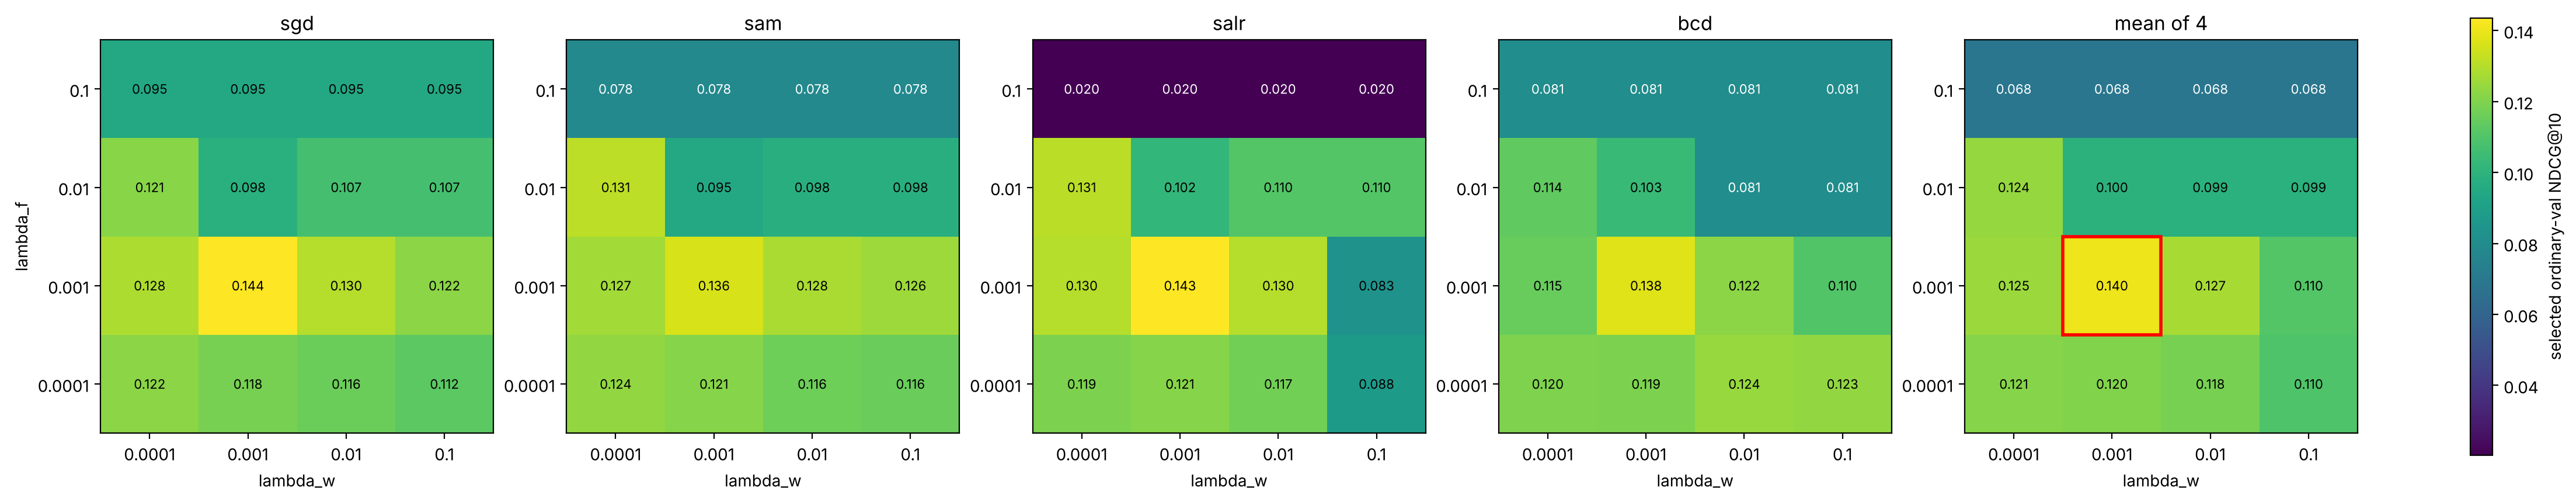

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.4), constrained_layout=True)
labels = [f"{g:g}" for g in GRID]
panels = [(m, runs[runs.method == m].pivot(index="lambda_f", columns="lambda_w", values="val_ndcg")) for m in METHODS]
panels.append(("mean of 4", pairs.pivot(index="lambda_f", columns="lambda_w", values="mean_ndcg")))
vmin = min(p.values.min() for _, p in panels); vmax = max(p.values.max() for _, p in panels)
for ax, (title, table) in zip(axes, panels):
    image = ax.imshow(table.values, origin="lower", cmap="viridis", vmin=vmin, vmax=vmax)
    for i in range(len(GRID)):
        for j in range(len(GRID)):
            ax.text(j, i, f"{table.values[i, j]:.3f}", ha="center", va="center", fontsize=8,
                    color="white" if table.values[i, j] < (vmin + vmax) / 2 else "black")
    ax.set(xticks=range(len(GRID)), xticklabels=labels, yticks=range(len(GRID)), yticklabels=labels,
           xlabel="lambda_w", title=title)
axes[0].set_ylabel("lambda_f")
i, j = GRID.index(chosen.lambda_f), GRID.index(chosen.lambda_w)
axes[-1].add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec="red", lw=2))
fig.colorbar(image, ax=axes, shrink=0.9, label="selected ordinary-val NDCG@10")
fig.savefig(RESULTS / "regularization_sweep.png", dpi=150, bbox_inches="tight")